In [1]:
print("testing run")

testing run


In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.dispatch import grid_flows, buy_price, feed_in_price, energy_cost, annual_bill

fc = pd.read_csv(ROOT / "results" / "forecasts.csv", index_col=0, parse_dates=True)
pv = pd.read_csv(ROOT / "data" / "processed" / "pv_hourly.csv", index_col=0, parse_dates=True)["pv_kwh"]
load = pd.read_csv(ROOT / "data" / "processed" / "household_load_hourly.csv",
                   index_col=0, parse_dates=True)["load_kwh"]
spot = fc["price_actual_mwh"]
assert (fc.index == pv.index).all() and (fc.index == load.index).all()
n_days = len(fc) / 24
print(len(fc), "hours =", n_days, "days")

8616 hours = 359.0 days


In [3]:
imp, exp = grid_flows(pv, load, p_battery_kw=0.0)
imp, exp = pd.Series(imp, index=fc.index), pd.Series(exp, index=fc.index)

residual = pv + imp - (load + exp)
print("Largest energy balance error (kWh):", residual.abs().max())

bill_A = annual_bill(imp, exp, spot, n_days)
bill_A.round(2)

Largest energy balance error (kWh): 8.881784197001252e-16


import_cost        832.17
export_revenue      87.23
supply_charge      434.89
total             1179.84
dtype: float64

In [4]:
print(f"Imported: {imp.sum():,.0f} kWh | Exported: {exp.sum():,.0f} kWh")
print(f"Share of exported kWh sent out while the spot price was negative: {100 * exp[spot < 0].sum() / exp.sum():.0f}%")
print(f"Average buy price: {buy_price(spot).mean() * 100:.1f} c/kWh | average spot price: {spot.mean() / 10:.1f} c/kWh")

no_solar = annual_bill(load.values, np.zeros(len(load)), spot, n_days)["total"]
print(f"Bill with no solar: ${no_solar:,.0f} | with solar, no battery: ${bill_A['total']:,.0f}")

Imported: 3,403 kWh | Exported: 5,326 kWh
Share of exported kWh sent out while the spot price was negative: 59%
Average buy price: 21.8 c/kWh | average spot price: 4.8 c/kWh
Bill with no solar: $1,742 | with solar, no battery: $1,180


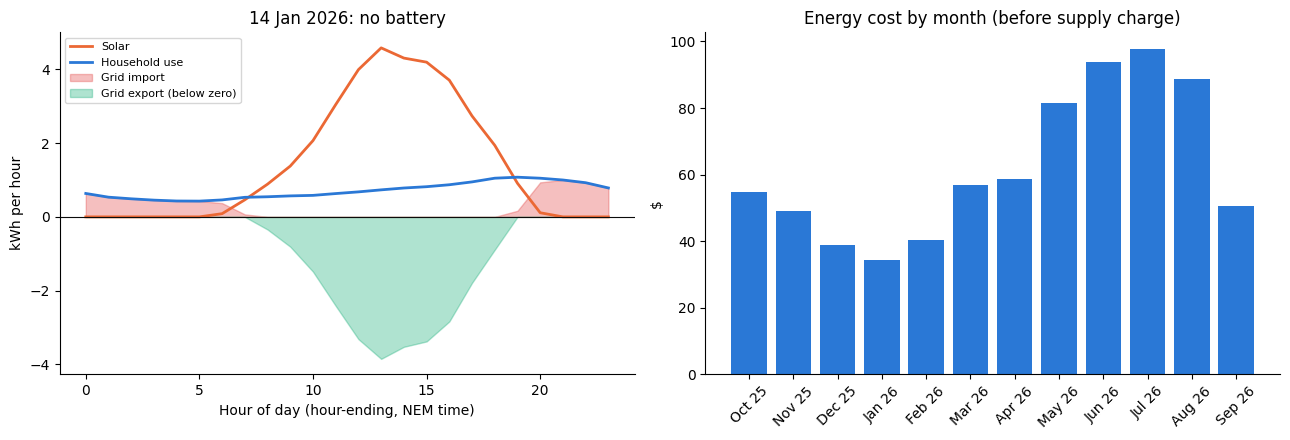

In [5]:
day = "2026-01-14"
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
h = pv[day].index.hour
axes[0].plot(h, pv[day].values, color="#eb6834", lw=2, label="Solar")
axes[0].plot(h, load[day].values, color="#2a78d6", lw=2, label="Household use")
axes[0].fill_between(h, imp[day].values, color="#e34948", alpha=0.35, label="Grid import")
axes[0].fill_between(h, -exp[day].values, color="#1baf7a", alpha=0.35, label="Grid export (below zero)")
axes[0].axhline(0, color="#0b0b0b", lw=0.8)
axes[0].set_title("14 Jan 2026: no battery"); axes[0].set_ylabel("kWh per hour")
axes[0].set_xlabel("Hour of day (hour-ending, NEM time)"); axes[0].legend(fontsize=8)

monthly = pd.Series(energy_cost(imp, exp, spot), index=fc.index).resample("MS").sum()
axes[1].bar(monthly.index.strftime("%b %y"), monthly.values, color="#2a78d6")
axes[1].set_title("Energy cost by month (before supply charge)"); axes[1].set_ylabel("$")
axes[1].tick_params(axis="x", rotation=45)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(ROOT / "results" / "fig_no_battery_balance.png", dpi=150)
plt.show()